## 1. Import Lib

In [1]:
# !pip install tensorflow==2.16.1

In [2]:
import pandas as pandas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import const
import joblib
from datetime import datetime
import random as python_random

from utils import *
from fuzzywuzzy import process
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import tensorflow as tf

pd.options.mode.chained_assignment = None  # Silencia o warning de atribuição encadeada

seed = 42
np.random.seed(seed)
python_random.seed(seed)
tf.random.set_seed(seed)




c:\Users\ti2\Documents\repos_pes\bootcamp_ds\projeto_analise_credito\env\Lib\site-packages\fuzzywuzzy\fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


## 2. Functions

In [3]:
def trattar_nulos(df):
    for col in df.columns:
        if df[col].dtype == 'object':
            moda = df[col].mode()[0]
            df.loc[:, col] = df[col].fillna(moda)
        else:
            median = df[col].median()
            df.loc[:, col] = df[col].fillna(median)
            
    return df
    

# Função para correção de erros de digitação
def corrigir_erros_digitacao(df, coluna, lista_valida):
    for i, valor in enumerate( df[coluna] ):
        valor_str = str(valor) if pd.notnull( valor ) else valor

        if valor_str not in lista_valida and pd.notnull( valor_str ):
            correcao = process.extractOne( valor_str, lista_valida )
            df.at[i, coluna ] = correcao


# Função para tratamento de Outiliers
def tratar_outliers( df, coluna, min_, max_ ):
    mediana = df [ ( df[coluna] >= min_) & ( df[coluna] <= max_) ][coluna].median()
    df[coluna] = df[coluna].apply( lambda x: mediana if x < min_ or x > max_ else x )
    return df


def save_scalers( df, nome_colunas):
    for nome_coluna in nome_colunas:
        scaler = StandardScaler()
        df[nome_coluna] = scaler.fit_transform( df[[nome_coluna]] )
        joblib.dump( scaler, f'./objetcs/scaler_{nome_coluna}.joblib' )

    return df

def save_label( df, nome_colunas):
    for nome_coluna in nome_colunas:
        label_encoder = LabelEncoder()
        df[nome_coluna] = label_encoder.fit_transform( df[nome_coluna] )
        joblib.dump( label_encoder, f'./objetcs/label_{nome_coluna}.joblib' )

    return df

def save_onehot( df, nome_colunas):
    for nome_coluna in nome_colunas:
        one_hot = OneHotEncoder()
        df[nome_coluna] = one_hot.fit_transform( df[[nome_coluna]] )
        joblib.dump( one_hot, f'./objetcs/onehot_{nome_coluna}.joblib' )

    return df

## 3. Loading Data


In [4]:
df = fetch_data_from_db(const.consulta_sql)

In [5]:
df.head()

,profissao,tempoprofissao,renda,tiporesidencia,escolaridade,score,idade,dependentes,estadocivil,produto,valorsolicitado,valortotalbem,classe
0,Cientista de Dados,24,58660.0,Outros,Ens.Médio,MuitoBom,58.0,0,Solteiro,VoyageRoamer,84623.00,350000.00,Bom
1,Empresário,21,46557.0,Outros,Ens.Médio,MuitoBom,37.0,2,Víuvo,EcoPrestige,126855.00,500000.00,Bom
2,Dentista,13,43939.0,Própria,Ens.Médio,Bom,23.0,0,Casado,DoubleDuty,127151.00,320000.00,Ruim
3,Engenheiro,10,37262.0,Própria,Superior,Baixo,35.0,0,Divorciado,AgileXplorer,28767.00,250000.00,Bom
4,Contador,6,52606.0,Própria,PósouMais,Justo,27.0,0,Casado,TrailConqueror,199564.00,400000.00,Ruim


## 4. EDA

In [6]:
df.shape

(150, 13)

In [7]:
df.dtypes

profissao           object
tempoprofissao       int64
renda              float64
tiporesidencia      object
escolaridade        object
score               object
idade              float64
dependentes          int64
estadocivil         object
produto             object
valorsolicitado     object
valortotalbem       object
classe              object
dtype: object

In [8]:
print( df.isna().sum() )

df.isna().mean() * 100

profissao          3
tempoprofissao     0
renda              0
tiporesidencia     3
escolaridade       0
score              0
idade              0
dependentes        0
estadocivil        0
produto            0
valorsolicitado    0
valortotalbem      0
classe             0
dtype: int64


profissao          2.0
tempoprofissao     0.0
renda              0.0
tiporesidencia     2.0
escolaridade       0.0
score              0.0
idade              0.0
dependentes        0.0
estadocivil        0.0
produto            0.0
valorsolicitado    0.0
valortotalbem      0.0
classe             0.0
dtype: float64

In [9]:
df.columns

Index(['profissao', 'tempoprofissao', 'renda', 'tiporesidencia',
       'escolaridade', 'score', 'idade', 'dependentes', 'estadocivil',
       'produto', 'valorsolicitado', 'valortotalbem', 'classe'],
      dtype='object')

In [10]:
cat = ['profissao', 'tiporesidencia', 'escolaridade', 'score',
        'estadocivil', 'produto', 'classe']

num = ['tempoprofissao','renda','idade', 'dependentes',  'valorsolicitado','valortotalbem']


array([[<Axes: title={'center': 'tempoprofissao'}>,
        <Axes: title={'center': 'renda'}>],
       [<Axes: title={'center': 'idade'}>,
        <Axes: title={'center': 'dependentes'}>]], dtype=object)

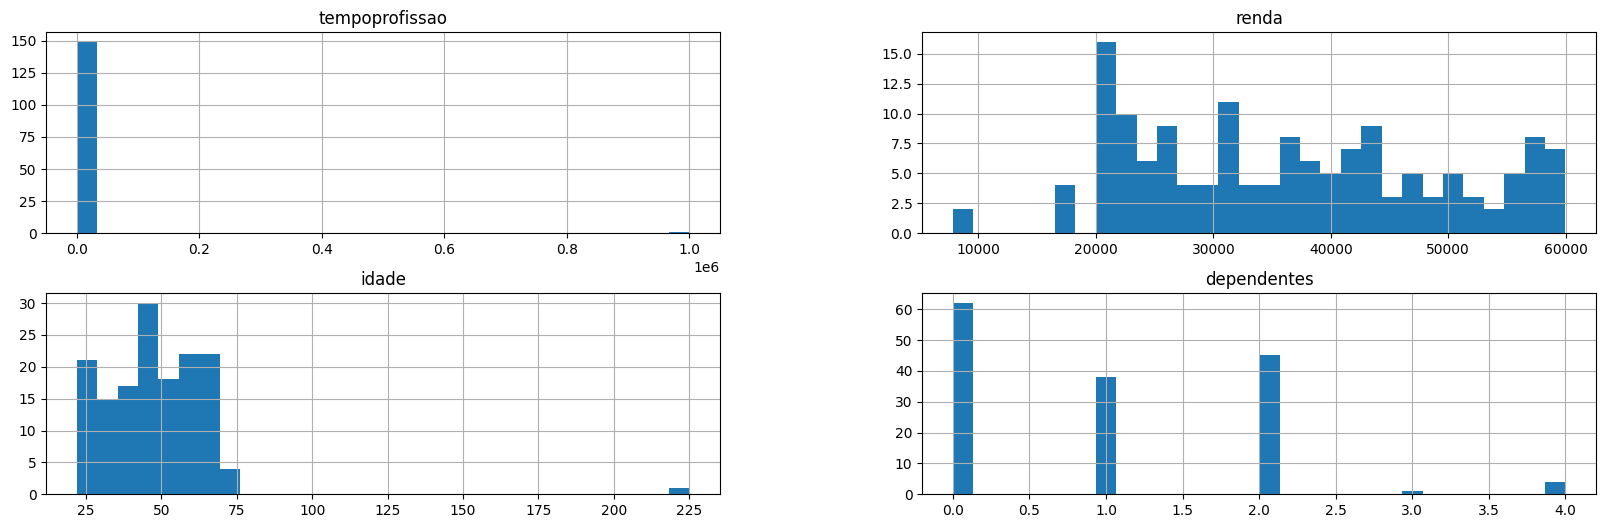

In [11]:
df.hist(bins=30, figsize=( 20,6))

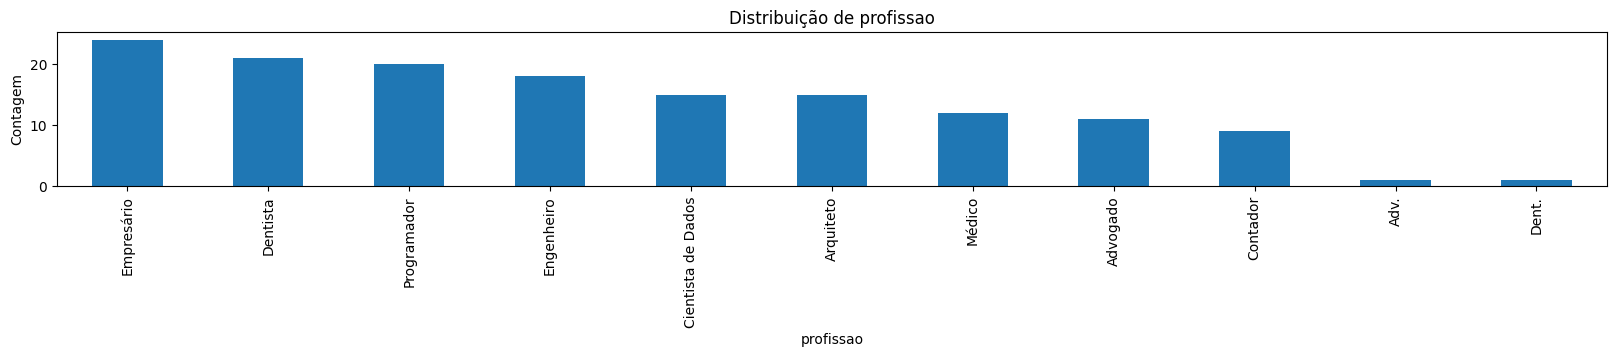

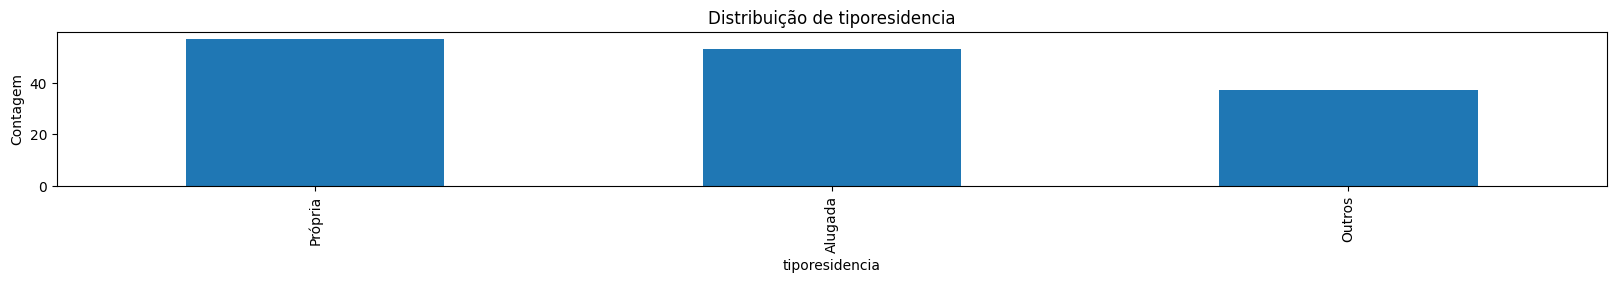

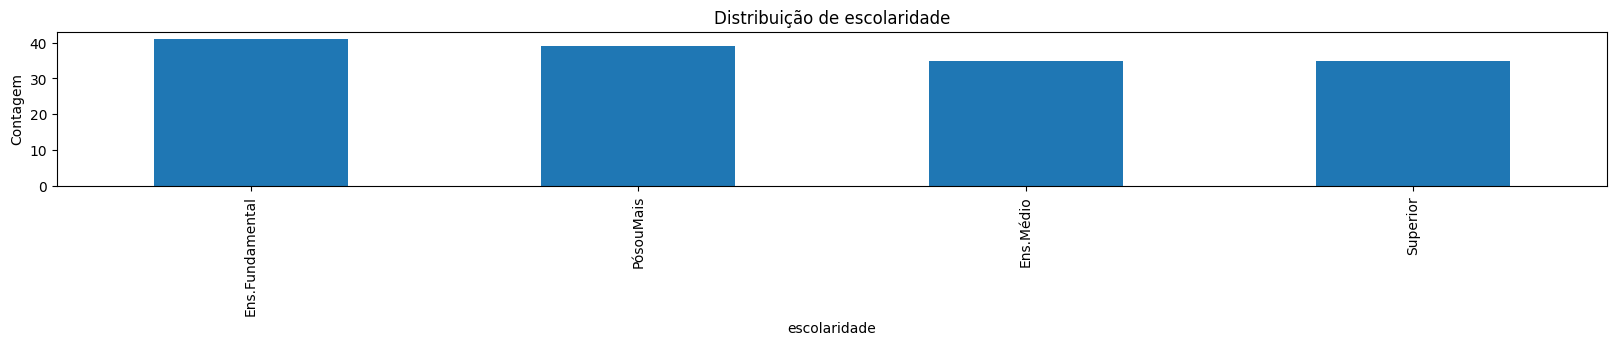

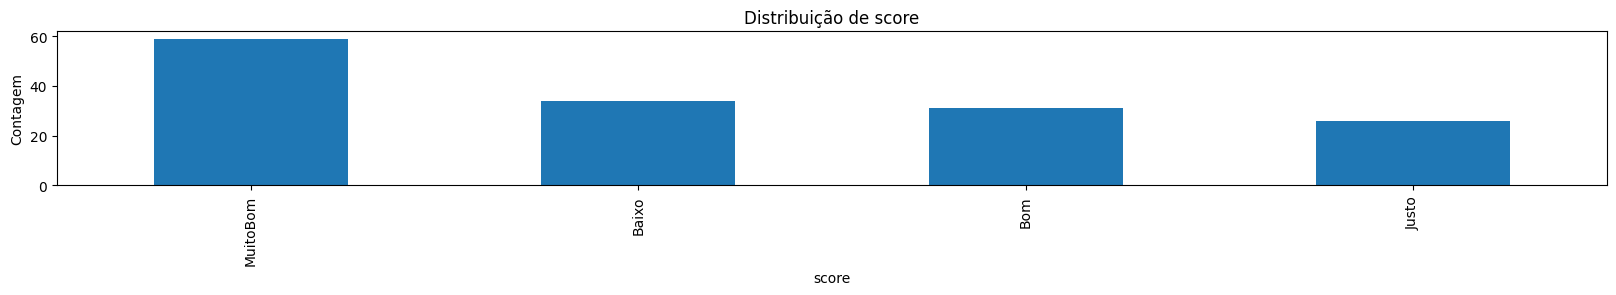

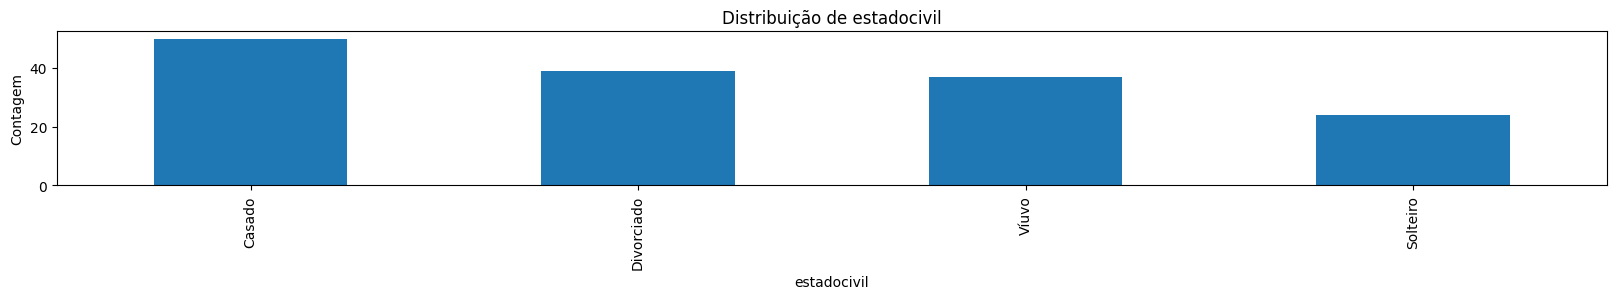

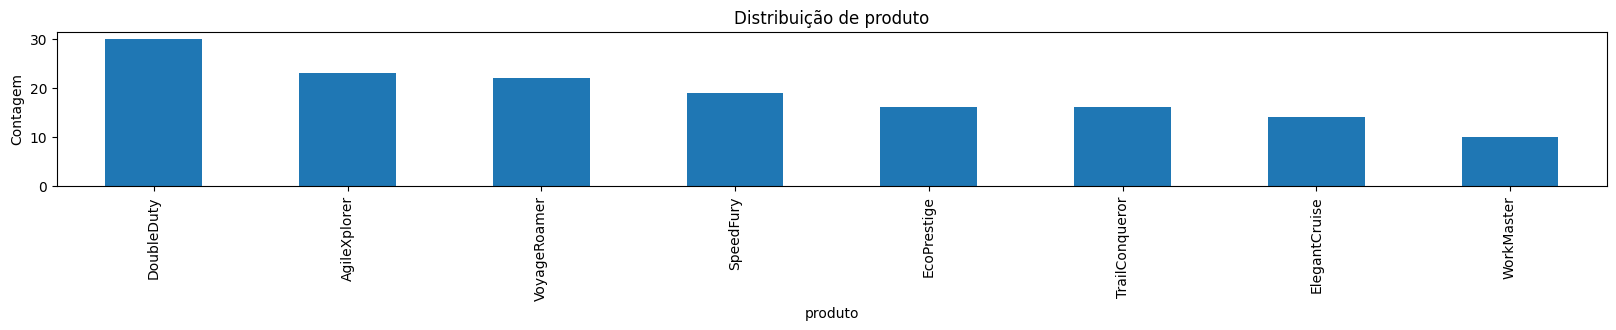

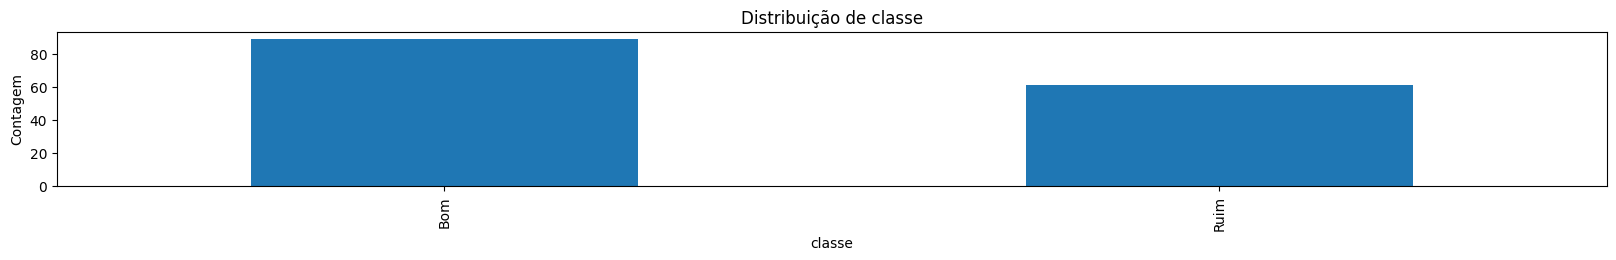

In [12]:

for col in cat:
    df[col].value_counts().plot( kind='bar', figsize=(20,2))
    plt.title(f'Distribuição de {col}')
    plt.ylabel('Contagem')
    plt.xlabel(col)
    plt.show()

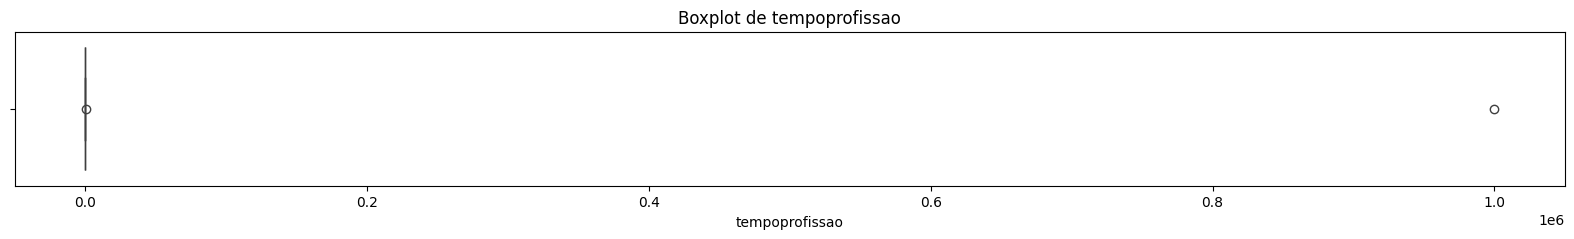

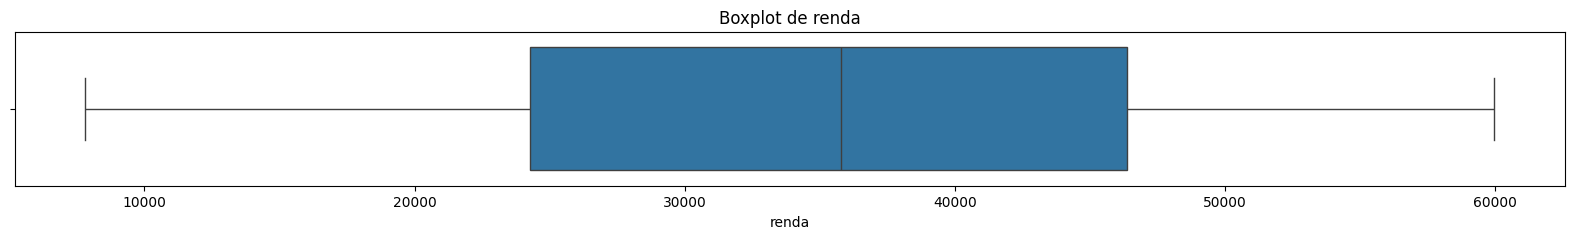

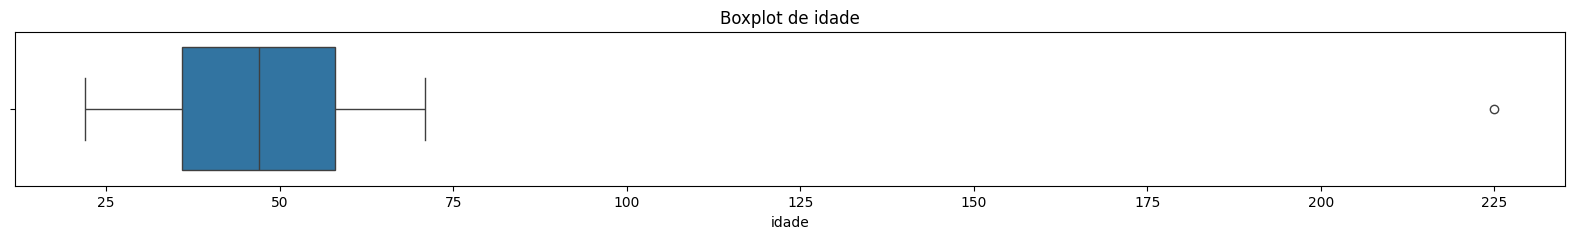

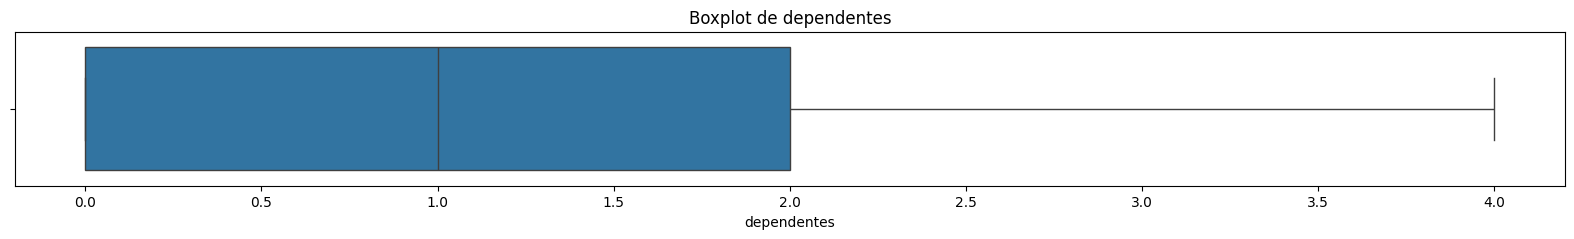

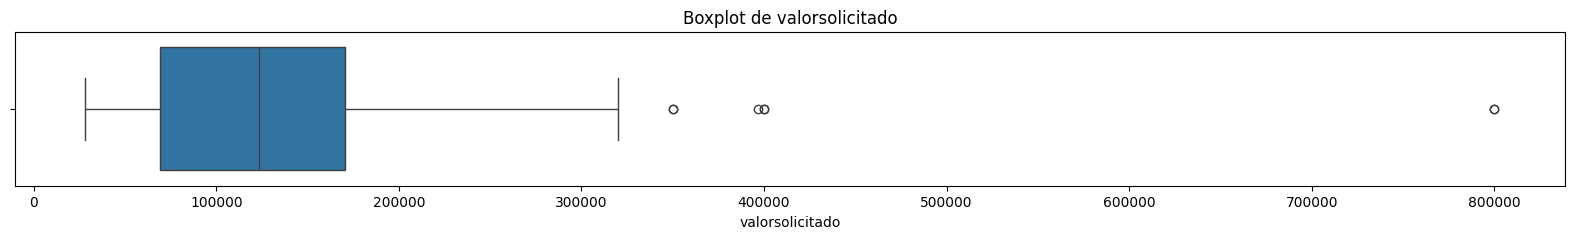

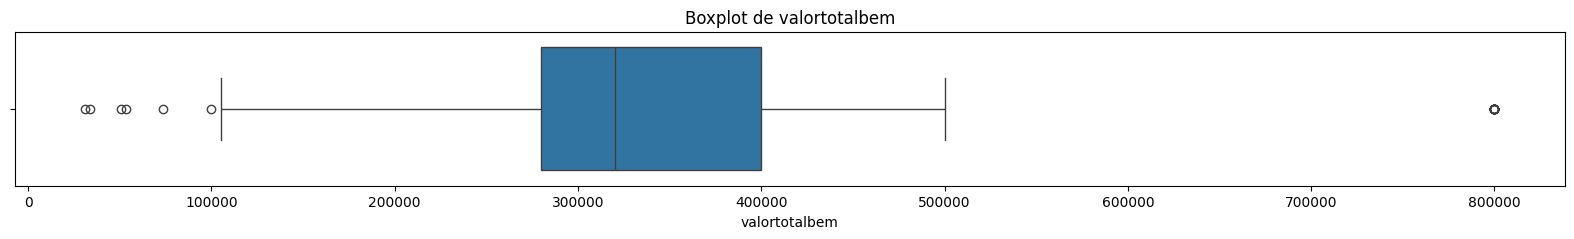

In [13]:
for col in num:
    plt.figure(figsize=(20,2) )
    sns.boxplot( data=df, x=col )
    plt.title(f'Boxplot de {col}')
    plt.show()
    

In [14]:
df.describe()

,tempoprofissao,renda,idade,dependentes
count,150.000000,150.000000,150.000000,150.000000
mean,6690.573333,36406.813333,48.086667,0.980000
std,81647.612861,12974.282533,20.056945,0.993063
min,0.000000,7814.000000,22.000000,0.000000
25%,13.000000,24271.750000,36.000000,0.000000
50%,24.000000,35795.000000,47.000000,1.000000
75%,32.750000,46361.000000,58.000000,2.000000
max,999999.000000,59976.000000,225.000000,4.000000


## 5. Tratamento dos dados

In [15]:
df1 = df.copy()

In [16]:
df1['idade'] = df1['idade'].astype(int)
df1['valorsolicitado'] = df1['valorsolicitado'].astype(float)
df1['valortotalbem'] = df1['valortotalbem'].astype(float)

# Trantamento de Dados Nulos
trattar_nulos(df1)

# Tratamento de erros de digitação
profissoes_validas = ['Advogado', 'Arquiteto','Cientista de Dados','Contador','Dentista', 'Empresário','Engenheiro','Médico','Prgramador']

corrigir_erros_digitacao( df1, 'profissao', profissoes_validas )

# Tratamento de Outiliers
df1 = tratar_outliers( df1, 'tempoprofissao', 0, 70 )
df1 = tratar_outliers( df1, 'idade', 0, 100 )




## 6. Feature Engineering

In [17]:
df1['proporcao_solicitado_total'] = df1['valorsolicitado'] / df1['valortotalbem']
df1['proporcao_solicitado_total'] = df1['proporcao_solicitado_total'].astype(float)


## 7. Separação Treino e Teste

In [18]:
X = df1.drop('classe', axis=1)
y = df1['classe']

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=seed )

## 8. Normalização

In [19]:
X_test = save_scalers( X_test, ['tempoprofissao','renda','idade','dependentes','valorsolicitado','valortotalbem','proporcao_solicitado_total'])

X_train = save_scalers( X_train, ['tempoprofissao','renda','idade','dependentes','valorsolicitado','valortotalbem','proporcao_solicitado_total'])



## 9. Codificação

In [20]:
map_ = {'Ruim': 0, 'Bom': 1 }

for col in ['profissao', 'tiporesidencia', 'escolaridade', 'score', 'estadocivil', 'produto']:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)


y_train = np.array( [ map_[item] for item in y_train ] )
y_test = np.array( [ map_[item] for item in y_test ] )

X_train = save_label( X_train, ['profissao','tiporesidencia','escolaridade','score','estadocivil','produto'])
X_test  = save_label( X_test,  ['profissao','tiporesidencia','escolaridade','score','estadocivil','produto'])

## 8. Seleção de Atributos

In [ ]:

model = RandomForestClassifier()

selector = RFE(model, n_features_to_select=10, step=1)
selector = selector.fit(X_train, y_train)

X_train = selector.transform(X_train)
X_test = selector.transform(X_test)

joblib.dump(selector,'./objetcs/selector.joblib')

print(selector.support_)
print(selector.ranking_)

[ True  True  True False  True False  True False  True  True  True  True
  True]
[1 1 1 3 1 2 1 4 1 1 1 1 1]


## 9. Treinamento do Modelo

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense( 128, activation='relu', input_shape=(X_train.shape[1],)),
    # tf.keras.layers.Dense(0.3),
    tf.keras.layers.Dense(64, activation='relu'),
    # tf.keras.layers.Dense(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    # tf.keras.layers.Dense(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Configurando o otimizado
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Compilando o modelo
model.compile(optimizer=optimizer, loss= 'binary_crossentropy', metrics=['accuracy'])

# Treinamento do modelo
model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=500,
    batch_size=10,
    verbose=1
)

model.save('meu_modelo.keras')

# Previsões
y_pred = model.predict( X_test)
y_pred = ( y_pred > 0.5).astype(int)

# Avaliando o modelo
print('Avaliação do Modelo nos Dados de Teste')
model.evaluate( X_test, y_test)

# Métricas de Classificação
print('\nRelatório de Classificação')
print(classification_report( y_test, y_pred) )




Epoch 1/500


c:\Users\ti2\Documents\repos_pes\bootcamp_ds\projeto_analise_credito\env\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6072 - loss: 0.6592 - val_accuracy: 0.5833 - val_loss: 0.6429
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6557 - loss: 0.6055 - val_accuracy: 0.6250 - val_loss: 0.6388
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7176 - loss: 0.5891 - val_accuracy: 0.6250 - val_loss: 0.6240
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6742 - loss: 0.5616 - val_accuracy: 0.6250 - val_loss: 0.6174
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7805 - loss: 0.5407 - val_accuracy: 0.6667 - val_loss: 0.6159
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7997 - loss: 0.5190 - val_accuracy: 0.7083 - val_loss: 0.6154
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8066 - loss: 0.4936 - val_accuracy: 0.7083 - val_loss: 0.6212
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8512 - loss: 0.4685 - val_accuracy: 0.7083 - val_loss: 0

## 10. Explicalibilidade do Modelo

In [ ]:
!pip install lime

In [ ]:
# Função de Previsão Ajustada para LIME

def model_predict( data_asarray):
    data_asframe = pd.DataFrame( data_asarray, columns=X_train.columns)
    data_asframe = save_scalers( data_asframe, ['tempoprofissao','renda','dependentes','valorsolicitado','valortotalbem','proporcao_solicitado_total'] )
    data_asframe = save_label( data_asframe, ['profissao','tiporesidencia','escolaridade','score','estadocivil','produto'] ) 
    predictions = model.predict( data_asframe)

    return np.hstack(( 1-predictions, predictions ))

import lime
import lime.lime_tabular

# cria explainer
explainer = lime.lime_tabular.LimeTabularExplainer( X_train.values,
                                                   feature_names=X_train.columns, class_names=['Ruim', 'Bom'], mode='classification')


exp = explainer.explain_instance( X_test.values[1], model_predict, num_features=10 )

# gerando HTML
exp.save_to_file('lime_explanation.html')

print('Pesos da target Bom\n')
if 1 in exp.local_exp:
    for feature, weight in exp.local_exp[1]:
        print(f'{feature}: {weight}')

print('\nFeature Importance')
feature_importance = exp.as_list(label=1)
for feature, weight in feature_importance:
        print(f'{feature}: {weight}')


AttributeError: 'numpy.ndarray' object has no attribute 'values'